### Sonic Log Generation and Comprehensive AI Workflow

### Key Features:
Data Generation: Creates synthetic well log data with realistic relationships between features (GR, RHOB, NPHI, RT, CALI) and the target sonic log (DT).

#### Exploratory Data Analysis:

Statistical summaries

Correlation analysis

Visualizations of distributions and relationships

#### Machine Learning Modeling:

Random Forest Regressor

Gradient Boosting Regressor

Linear Regression

Ridge Regression

Support Vector Regression (SVR)

#### Model Evaluation:

Multiple metrics (R², RMSE, MAE)

Cross-validation

Comparative analysis

Residual analysis

#### Feature Importance:

Random Forest feature importance

Permutation importance

Comparative analysis

#### Depth-Based Analysis:

Comprehensive log visualization

Original vs predicted comparisons

Depth-based error analysis

#### Outputs:
Generated synthetic sonic logs with predictions

Model performance comparisons

Feature importance rankings

Comprehensive visualizations

CSV files with results

#### The program creates realistic synthetic data that mimics real well log relationships and demonstrates a complete machine learning workflow for petrophysical analysis. 
#### You can adjust the n_samples parameter and modify the data generation logic to create different scenarios.

#### Keith R. Holdaway FGS

Step 1: Generating Synthetic Well Log Data...
Generated 1000 samples
Features: GR (Gamma Ray), RHOB (Density), NPHI (Neutron Porosity), RT (Resistivity), CALI (Caliper)
Target: DT (Sonic Transit Time)

Step 2: Exploratory Data Analysis...

Basic Statistics:
             DEPTH           GR         RHOB         NPHI           RT  \
count  1000.000000  1000.000000  1000.000000  1000.000000  1000.000000   
mean   2000.000000    22.336415     2.086931     0.126482     2.525369   
std     578.217089    12.025540     0.298288     0.140586     1.730894   
min    1000.000000     6.515567     1.425286    -0.102167     1.233752   
25%    1500.000000    17.115645     1.822489    -0.004608     1.711774   
50%    2000.000000    20.486884     2.078827     0.101101     2.082154   
75%    2500.000000    23.868023     2.348597     0.260298     2.563564   
max    3000.000000   109.003894     2.703599     0.402139    13.233873   

              CALI           DT  
count  1000.000000  1000.000000  
mean   

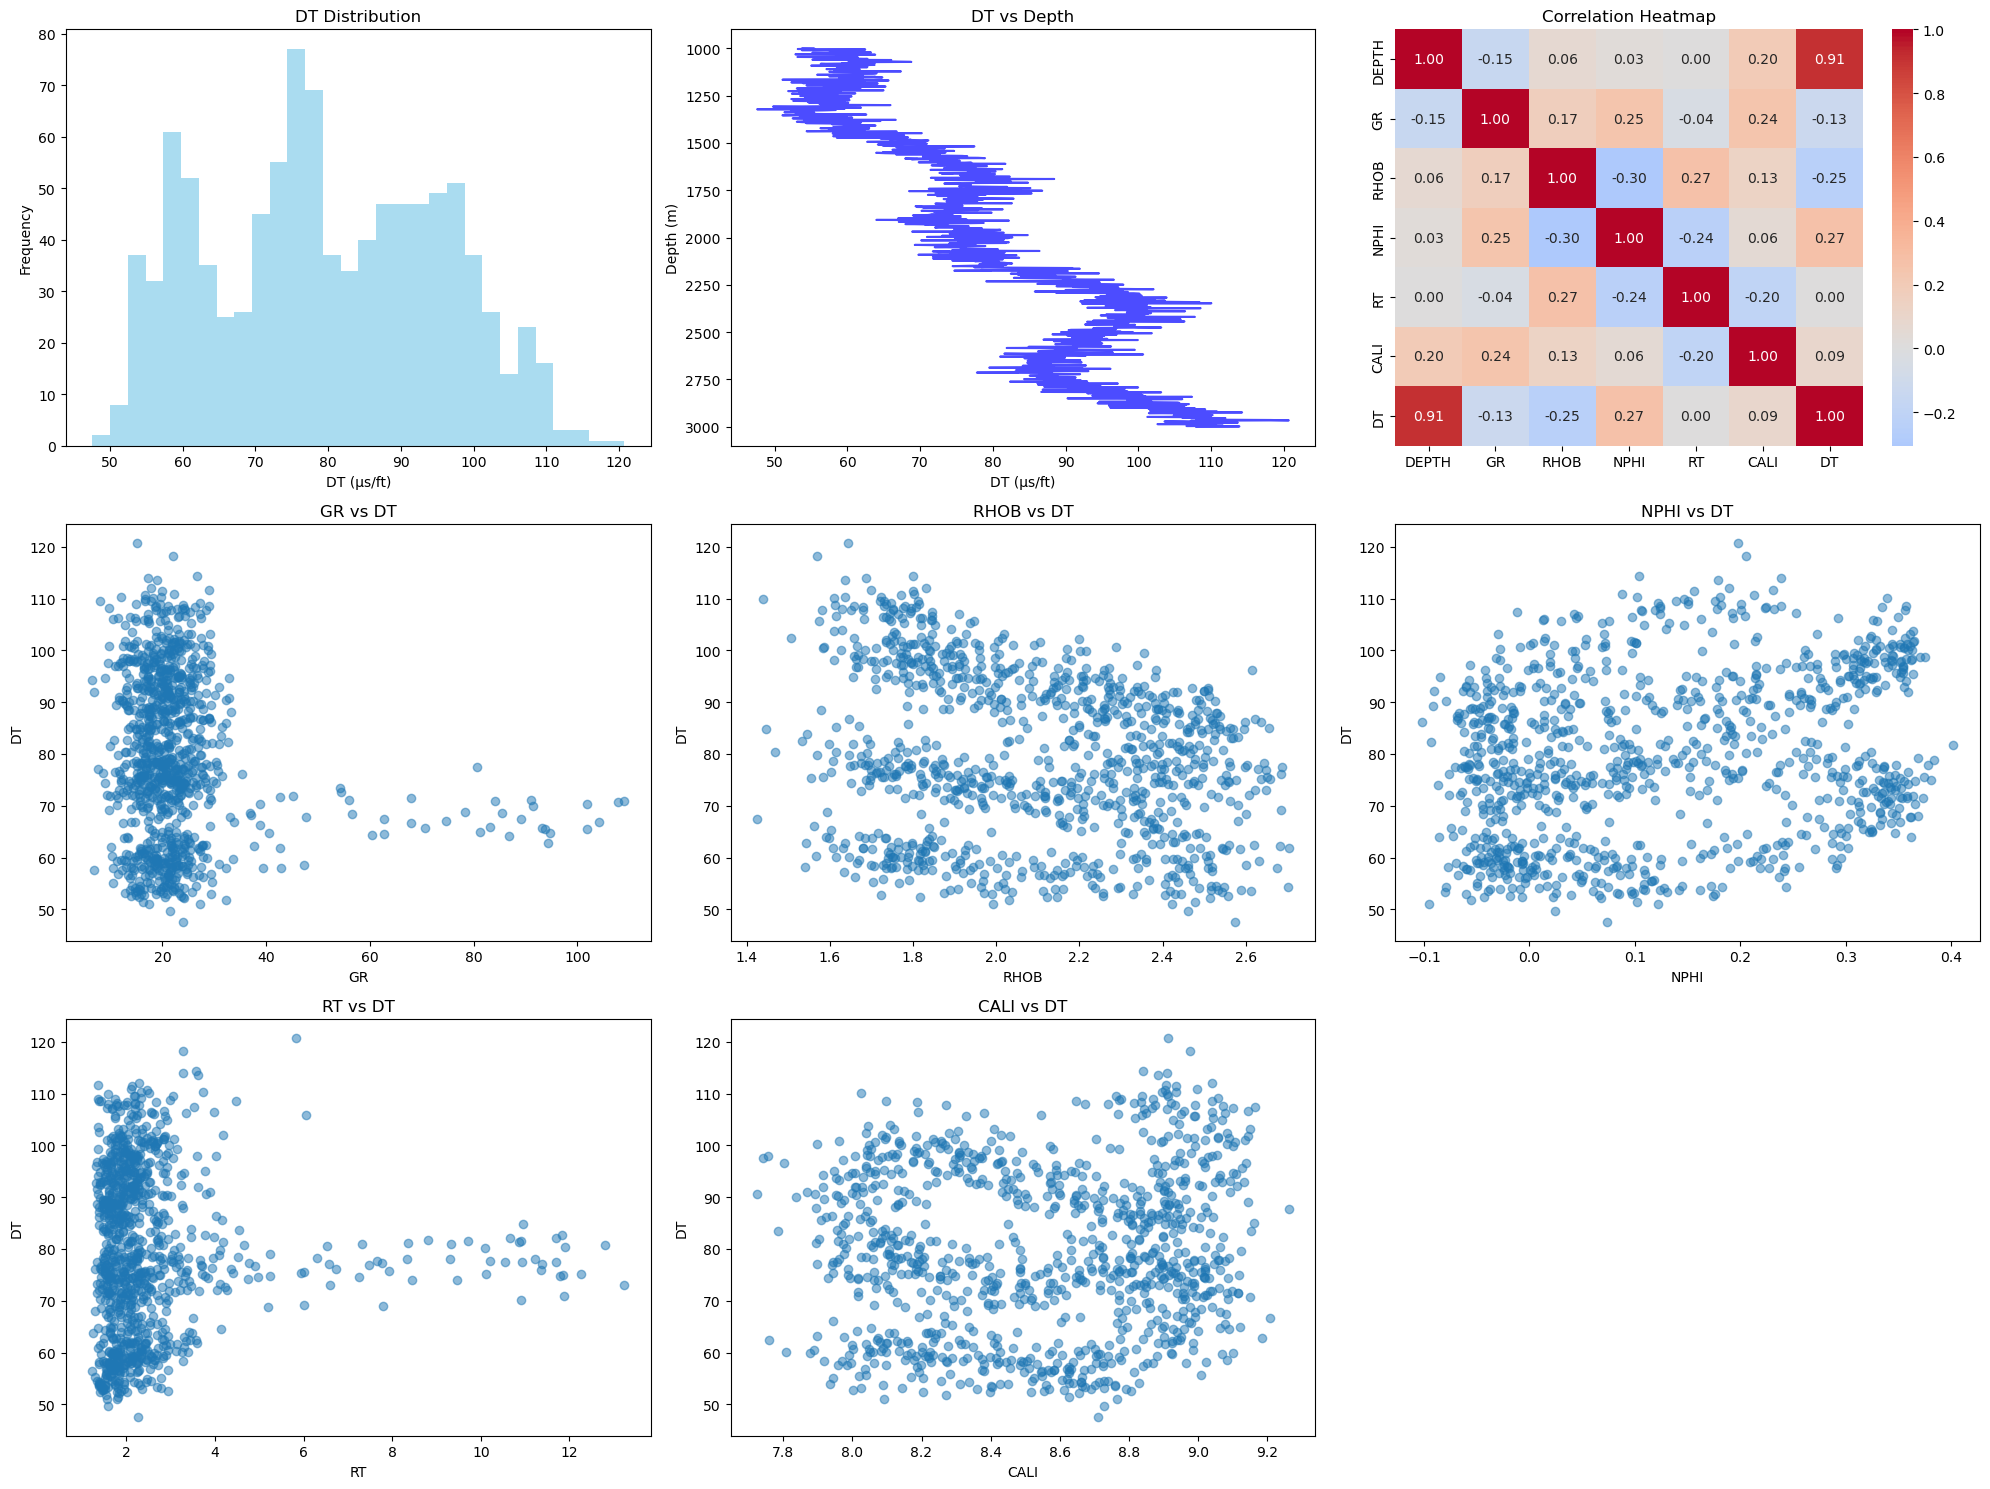


Step 3: Data Preprocessing...
Training set: 800 samples
Testing set: 200 samples

Step 4: Machine Learning Modeling...

Training Random Forest...
Random Forest - R²: 0.7039, RMSE: 8.4586

Training Gradient Boosting...
Gradient Boosting - R²: 0.7062, RMSE: 8.4256

Training Linear Regression...
Linear Regression - R²: 0.1165, RMSE: 14.6107

Training Ridge Regression...
Ridge Regression - R²: 0.1192, RMSE: 14.5887

Training Support Vector Regression...
Support Vector Regression - R²: 0.6282, RMSE: 9.4783

Model Performance Summary:
                       Model     RMSE       MSE      MAE      R2  CV R2 Mean  \
0              Random Forest   8.4586   71.5485   5.3388  0.7039      0.7337   
1          Gradient Boosting   8.4256   70.9903   6.2876  0.7062      0.6746   
2          Linear Regression  14.6107  213.4724  13.2787  0.1165      0.1401   
3           Ridge Regression  14.5887  212.8304  13.2764  0.1192      0.1400   
4  Support Vector Regression   9.4783   89.8381   6.7355  0.6282

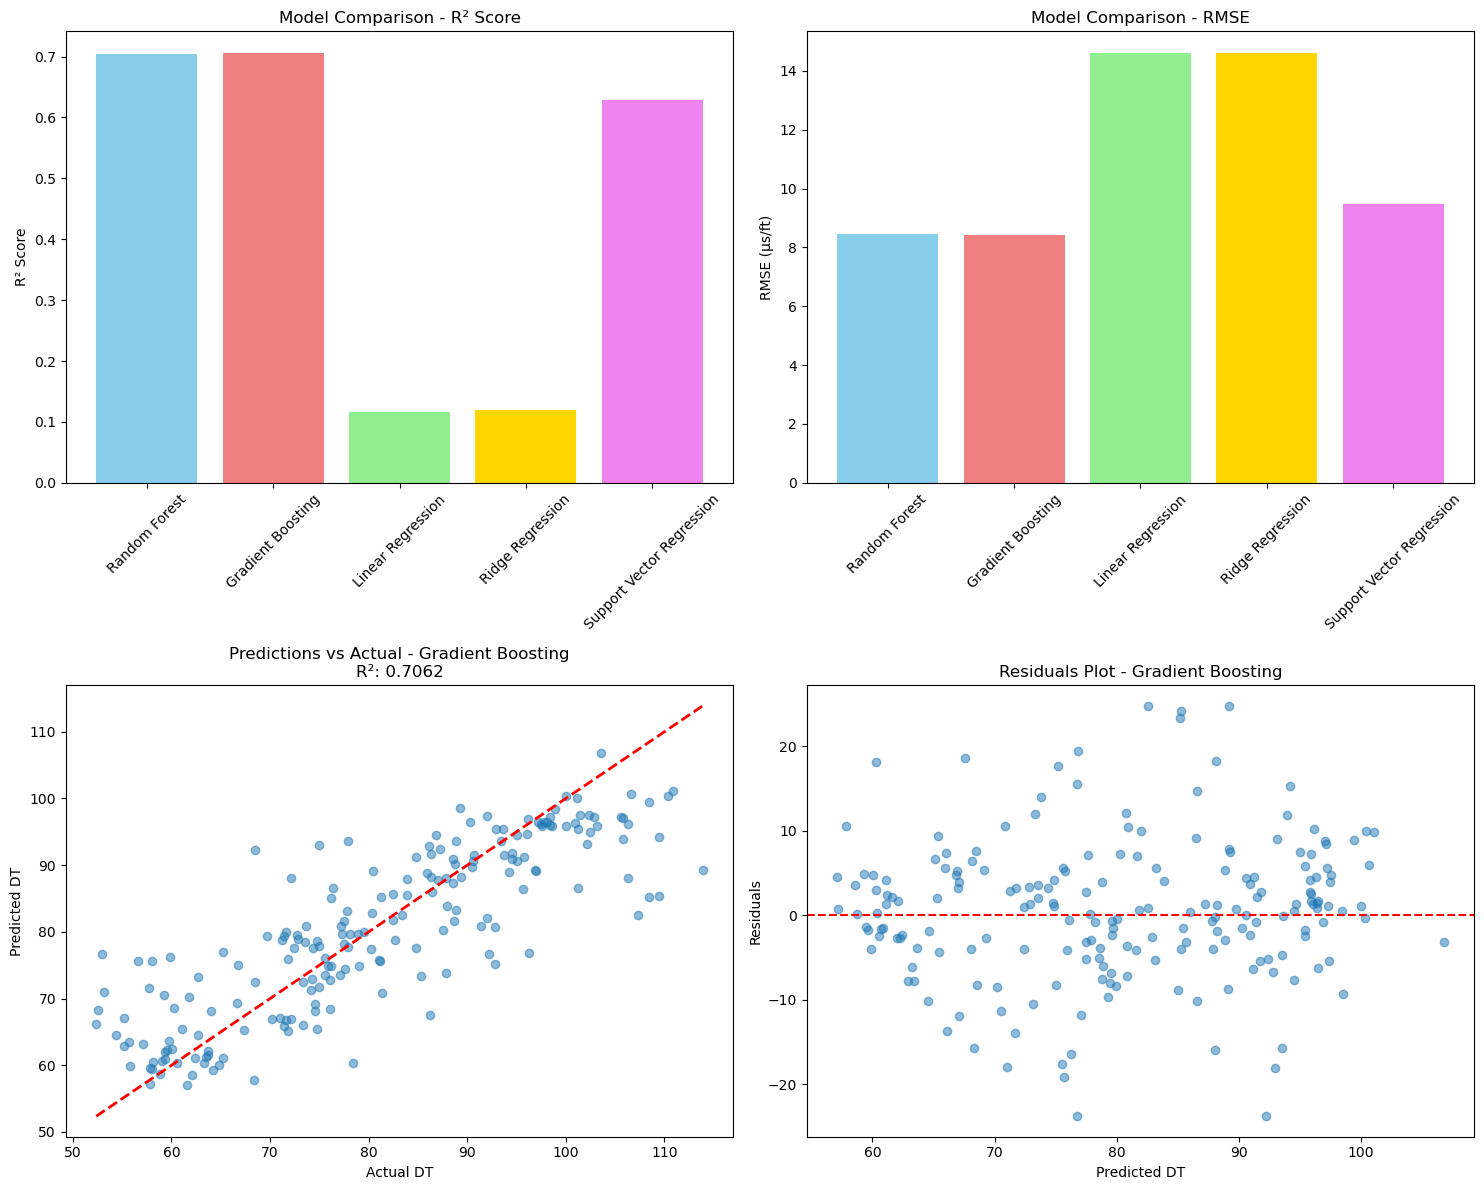


Best Model: Gradient Boosting

Step 6: Feature Importance Analysis...
Feature Importance (Random Forest):
  Feature  Importance
4    CALI    0.372808
1    RHOB    0.276812
2    NPHI    0.262606
3      RT    0.051866
0      GR    0.035909


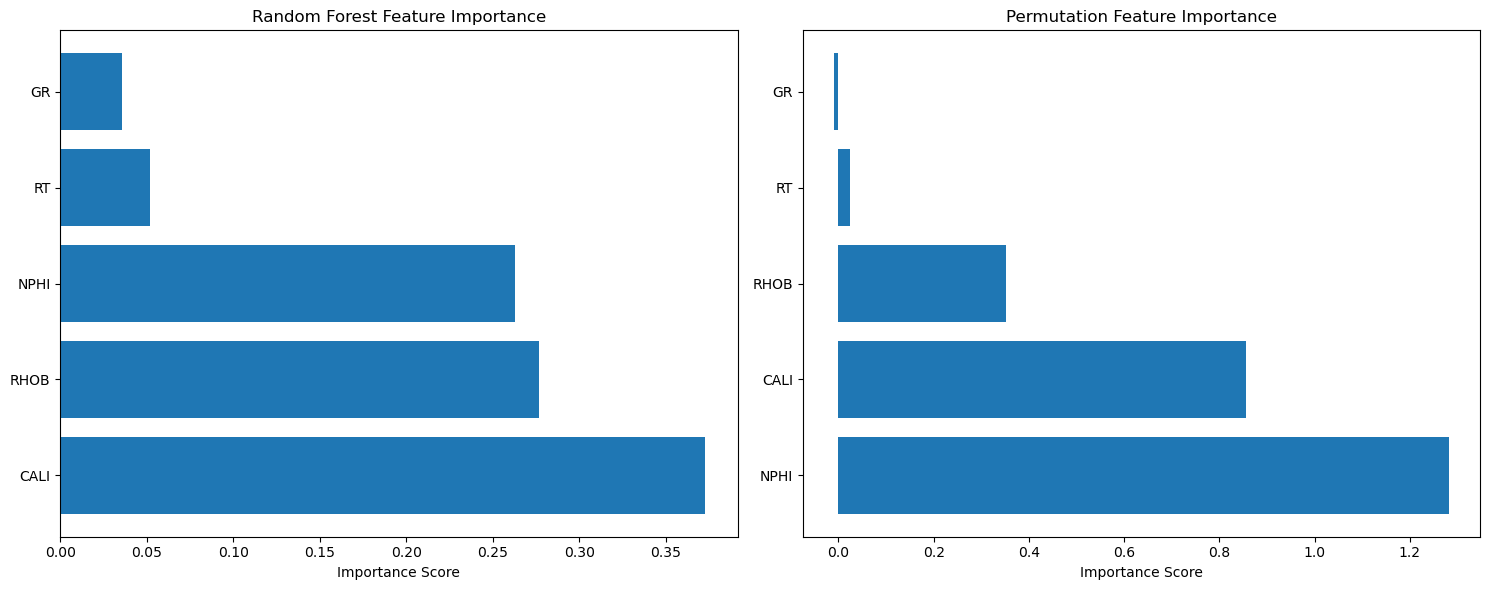


Step 7: Depth-Based Analysis...


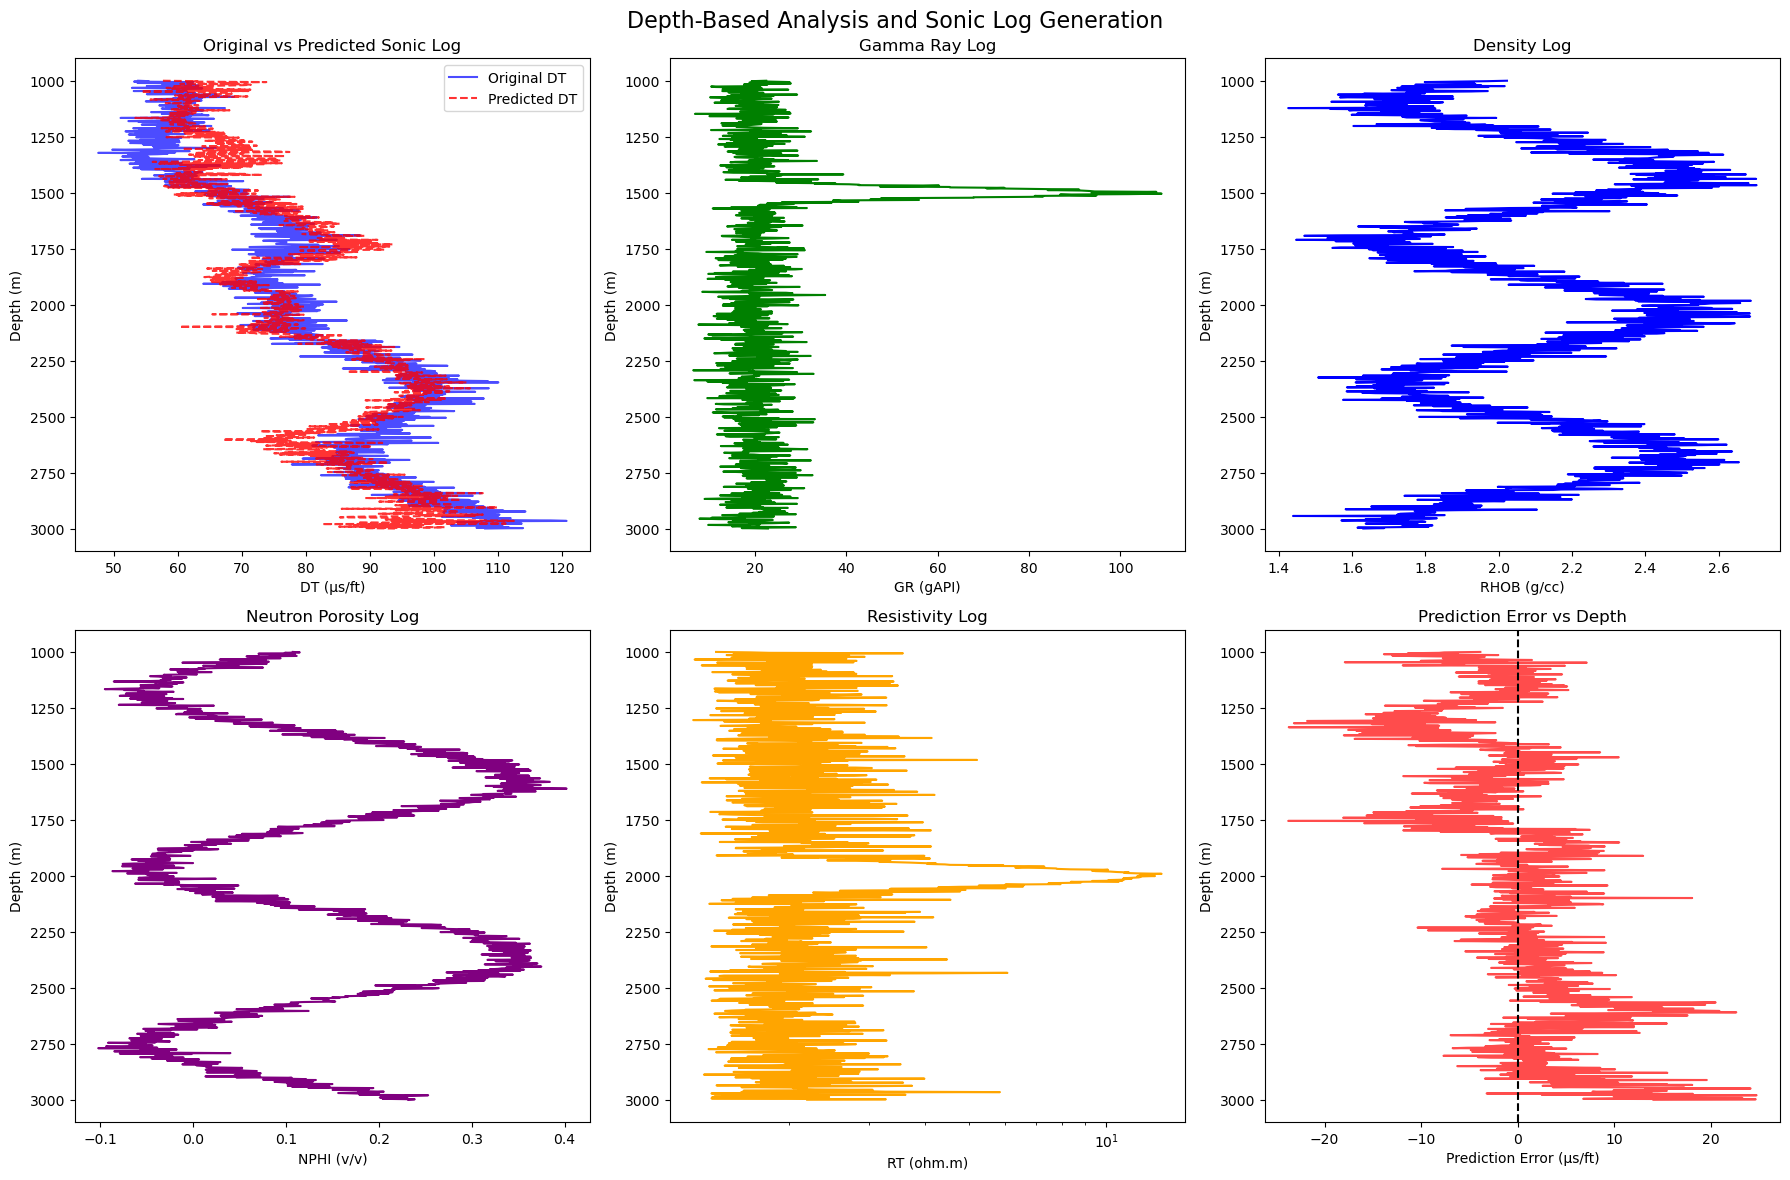


Depth-based analysis completed.
Average prediction error: 5.0216 μs/ft
Maximum prediction error: 24.7674 μs/ft

WORKFLOW COMPLETED SUCCESSFULLY!

FINAL RESULTS:
Best Model: Gradient Boosting
R² Score: 0.7062
RMSE: 8.4256 μs/ft
MAE: 6.2876 μs/ft

Results saved to 'generated_sonic_logs.csv' and 'model_performance.csv'


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')

class SonicLogGenerator:
    def __init__(self, n_samples=1000, random_state=42):
        self.n_samples = n_samples
        self.random_state = random_state
        np.random.seed(random_state)
        self.data = None
        self.models = {}
        self.scaler = StandardScaler()
        self.feature_importance = {}
        
    def generate_synthetic_data(self):
        """Generate synthetic well log data"""
        print("Step 1: Generating Synthetic Well Log Data...")
        
        # Depth values (meters)
        depth = np.linspace(1000, 3000, self.n_samples)
        
        # Generate synthetic features with realistic relationships
        # GR - Gamma Ray (gAPI)
        gr = 20 + 80 * np.exp(-0.001 * (depth - 1500)**2) + np.random.normal(0, 5, self.n_samples)
        
        # RHOB - Bulk Density (g/cc)
        rhob = 2.1 + 0.4 * np.sin(0.01 * depth) + 0.1 * np.random.normal(0, 1, self.n_samples)
        
        # NPHI - Neutron Porosity (v/v)
        nphi = 0.15 + 0.2 * np.cos(0.008 * depth) + 0.02 * np.random.normal(0, 1, self.n_samples)
        
        # RT - Resistivity (ohm.m)
        rt = 1 + 10 * np.exp(-0.0005 * (depth - 2000)**2) + np.random.lognormal(0, 0.5, self.n_samples)
        
        # CALI - Caliper (inches)
        cali = 8.5 + 0.5 * np.sin(0.005 * depth) + 0.1 * np.random.normal(0, 1, self.n_samples)
        
        # Generate synthetic DT (Sonic Log - μs/ft) with realistic relationships
        # DT is inversely related to RHOB and has complex relationships with other logs
        dt_base = 40 + 60 * (1 / (1 + np.exp(-0.002 * (depth - 2000))))  # S-curve
        dt_gr_effect = 0.5 * (gr - np.mean(gr)) / np.std(gr)  # GR effect
        dt_rhob_effect = -15 * (rhob - 2.3)  # Density effect (negative correlation)
        dt_nphi_effect = 20 * nphi  # Porosity effect
        dt_rt_effect = 5 * np.log(rt)  # Resistivity effect
        
        # Combine effects with noise
        dt = (dt_base + dt_gr_effect + dt_rhob_effect + dt_nphi_effect + 
              dt_rt_effect + np.random.normal(0, 3, self.n_samples))
        
        # Ensure DT stays in realistic range
        dt = np.clip(dt, 40, 140)
        
        # Create DataFrame
        self.data = pd.DataFrame({
            'DEPTH': depth,
            'GR': gr,
            'RHOB': rhob,
            'NPHI': nphi,
            'RT': rt,
            'CALI': cali,
            'DT': dt  # Target variable
        })
        
        print(f"Generated {len(self.data)} samples")
        print("Features: GR (Gamma Ray), RHOB (Density), NPHI (Neutron Porosity), RT (Resistivity), CALI (Caliper)")
        print("Target: DT (Sonic Transit Time)")
        
    def exploratory_data_analysis(self):
        """Perform exploratory data analysis"""
        print("\nStep 2: Exploratory Data Analysis...")
        
        # Basic statistics
        print("\nBasic Statistics:")
        print(self.data.describe())
        
        # Correlation matrix
        print("\nCorrelation Matrix:")
        correlation_matrix = self.data.corr()
        print(correlation_matrix['DT'].sort_values(ascending=False))
        
        # Create a larger figure for better visualization
        plt.figure(figsize=(20, 15))
        
        # First row of plots
        plt.subplot(3, 3, 1)
        plt.hist(self.data['DT'], bins=30, alpha=0.7, color='skyblue')
        plt.title('DT Distribution')
        plt.xlabel('DT (μs/ft)')
        plt.ylabel('Frequency')
        
        plt.subplot(3, 3, 2)
        plt.plot(self.data['DT'], self.data['DEPTH'], 'b-', alpha=0.7)
        plt.title('DT vs Depth')
        plt.xlabel('DT (μs/ft)')
        plt.ylabel('Depth (m)')
        plt.gca().invert_yaxis()
        
        plt.subplot(3, 3, 3)
        sns.heatmap(self.data.corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
        plt.title('Correlation Heatmap')
        
        # Feature relationships with DT
        features = ['GR', 'RHOB', 'NPHI', 'RT', 'CALI']
        for i, feature in enumerate(features):
            plt.subplot(3, 3, i + 4)  # Start from position 4 in 3x3 grid
            plt.scatter(self.data[feature], self.data['DT'], alpha=0.5)
            plt.xlabel(feature)
            plt.ylabel('DT')
            plt.title(f'{feature} vs DT')
        
        plt.tight_layout()
        plt.show()
        
    def preprocess_data(self):
        """Preprocess data for modeling"""
        print("\nStep 3: Data Preprocessing...")
        
        # Separate features and target
        X = self.data[['GR', 'RHOB', 'NPHI', 'RT', 'CALI']]
        y = self.data['DT']
        
        # Split the data
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=self.random_state
        )
        
        # Scale features
        X_train_scaled = self.scaler.fit_transform(X_train)
        X_test_scaled = self.scaler.transform(X_test)
        
        self.X_train, self.X_test = X_train, X_test
        self.X_train_scaled, self.X_test_scaled = X_train_scaled, X_test_scaled
        self.y_train, self.y_test = y_train, y_test
        
        print(f"Training set: {X_train.shape[0]} samples")
        print(f"Testing set: {X_test.shape[0]} samples")
        
    def train_models(self):
        """Train multiple machine learning models"""
        print("\nStep 4: Machine Learning Modeling...")
        
        # Define models
        models = {
            'Random Forest': RandomForestRegressor(n_estimators=100, random_state=self.random_state),
            'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=self.random_state),
            'Linear Regression': LinearRegression(),
            'Ridge Regression': Ridge(alpha=1.0),
            'Support Vector Regression': SVR(kernel='rbf', C=1.0)
        }
        
        # Train and evaluate each model
        results = []
        
        for name, model in models.items():
            print(f"\nTraining {name}...")
            
            # Use scaled data for SVR, original for others
            if name == 'Support Vector Regression':
                X_train_used, X_test_used = self.X_train_scaled, self.X_test_scaled
            else:
                X_train_used, X_test_used = self.X_train, self.X_test
            
            # Train model
            model.fit(X_train_used, self.y_train)
            
            # Predictions
            y_pred = model.predict(X_test_used)
            
            # Calculate metrics
            mse = mean_squared_error(self.y_test, y_pred)
            rmse = np.sqrt(mse)
            mae = mean_absolute_error(self.y_test, y_pred)
            r2 = r2_score(self.y_test, y_pred)
            
            # Cross-validation
            cv_scores = cross_val_score(model, X_train_used, self.y_train, 
                                      cv=5, scoring='r2')
            
            # Store results
            results.append({
                'Model': name,
                'RMSE': rmse,
                'MSE': mse,
                'MAE': mae,
                'R2': r2,
                'CV R2 Mean': cv_scores.mean(),
                'CV R2 Std': cv_scores.std()
            })
            
            # Store model
            self.models[name] = model
            
            print(f"{name} - R²: {r2:.4f}, RMSE: {rmse:.4f}")
        
        # Create results dataframe
        self.results_df = pd.DataFrame(results)
        print("\nModel Performance Summary:")
        print(self.results_df.round(4))
        
    def evaluate_models(self):
        """Evaluate and compare model performance"""
        print("\nStep 5: Model Evaluation...")
        
        # Plot model comparison
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        
        # R² comparison
        models = self.results_df['Model']
        r2_scores = self.results_df['R2']
        
        axes[0, 0].bar(models, r2_scores, color=['skyblue', 'lightcoral', 'lightgreen', 'gold', 'violet'])
        axes[0, 0].set_title('Model Comparison - R² Score')
        axes[0, 0].set_ylabel('R² Score')
        axes[0, 0].tick_params(axis='x', rotation=45)
        
        # RMSE comparison
        rmse_scores = self.results_df['RMSE']
        axes[0, 1].bar(models, rmse_scores, color=['skyblue', 'lightcoral', 'lightgreen', 'gold', 'violet'])
        axes[0, 1].set_title('Model Comparison - RMSE')
        axes[0, 1].set_ylabel('RMSE (μs/ft)')
        axes[0, 1].tick_params(axis='x', rotation=45)
        
        # Predictions vs Actual for best model
        best_model_name = self.results_df.loc[self.results_df['R2'].idxmax(), 'Model']
        best_model = self.models[best_model_name]
        
        if best_model_name == 'Support Vector Regression':
            X_test_used = self.X_test_scaled
        else:
            X_test_used = self.X_test
            
        y_pred_best = best_model.predict(X_test_used)
        
        axes[1, 0].scatter(self.y_test, y_pred_best, alpha=0.5)
        axes[1, 0].plot([self.y_test.min(), self.y_test.max()], 
                       [self.y_test.min(), self.y_test.max()], 'r--', lw=2)
        axes[1, 0].set_xlabel('Actual DT')
        axes[1, 0].set_ylabel('Predicted DT')
        axes[1, 0].set_title(f'Predictions vs Actual - {best_model_name}\nR²: {r2_score(self.y_test, y_pred_best):.4f}')
        
        # Residuals plot
        residuals = self.y_test - y_pred_best
        axes[1, 1].scatter(y_pred_best, residuals, alpha=0.5)
        axes[1, 1].axhline(y=0, color='r', linestyle='--')
        axes[1, 1].set_xlabel('Predicted DT')
        axes[1, 1].set_ylabel('Residuals')
        axes[1, 1].set_title(f'Residuals Plot - {best_model_name}')
        
        plt.tight_layout()
        plt.show()
        
        print(f"\nBest Model: {best_model_name}")
        
    def analyze_feature_importance(self):
        """Analyze feature importance"""
        print("\nStep 6: Feature Importance Analysis...")
        
        # Use Random Forest for feature importance (most interpretable)
        rf_model = self.models['Random Forest']
        
        # Get feature importance
        importance = rf_model.feature_importances_
        features = self.X_train.columns
        
        # Create feature importance dataframe
        feature_importance_df = pd.DataFrame({
            'Feature': features,
            'Importance': importance
        }).sort_values('Importance', ascending=False)
        
        print("Feature Importance (Random Forest):")
        print(feature_importance_df)
        
        # Plot feature importance
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
        
        # Random Forest importance
        ax1.barh(feature_importance_df['Feature'], feature_importance_df['Importance'])
        ax1.set_title('Random Forest Feature Importance')
        ax1.set_xlabel('Importance Score')
        
        # Permutation importance for comparison
        perm_importance = permutation_importance(
            rf_model, self.X_test, self.y_test, 
            n_repeats=10, random_state=self.random_state
        )
        
        perm_df = pd.DataFrame({
            'Feature': features,
            'Importance': perm_importance.importances_mean
        }).sort_values('Importance', ascending=False)
        
        ax2.barh(perm_df['Feature'], perm_df['Importance'])
        ax2.set_title('Permutation Feature Importance')
        ax2.set_xlabel('Importance Score')
        
        plt.tight_layout()
        plt.show()
        
        self.feature_importance = {
            'rf_importance': feature_importance_df,
            'permutation_importance': perm_df
        }
        
    def depth_based_analysis(self):
        """Perform depth-based analysis and visualization"""
        print("\nStep 7: Depth-Based Analysis...")
        
        # Use best model for predictions
        best_model_name = self.results_df.loc[self.results_df['R2'].idxmax(), 'Model']
        best_model = self.models[best_model_name]
        
        if best_model_name == 'Support Vector Regression':
            X_all_scaled = self.scaler.transform(self.data[['GR', 'RHOB', 'NPHI', 'RT', 'CALI']])
            predictions = best_model.predict(X_all_scaled)
        else:
            predictions = best_model.predict(self.data[['GR', 'RHOB', 'NPHI', 'RT', 'CALI']])
        
        # Create comprehensive depth plot
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        fig.suptitle('Depth-Based Analysis and Sonic Log Generation', fontsize=16)
        
        # Original vs Predicted DT
        axes[0, 0].plot(self.data['DT'], self.data['DEPTH'], 'b-', label='Original DT', alpha=0.7)
        axes[0, 0].plot(predictions, self.data['DEPTH'], 'r--', label='Predicted DT', alpha=0.8)
        axes[0, 0].set_xlabel('DT (μs/ft)')
        axes[0, 0].set_ylabel('Depth (m)')
        axes[0, 0].set_title('Original vs Predicted Sonic Log')
        axes[0, 0].legend()
        axes[0, 0].invert_yaxis()
        
        # GR log
        axes[0, 1].plot(self.data['GR'], self.data['DEPTH'], 'g-')
        axes[0, 1].set_xlabel('GR (gAPI)')
        axes[0, 1].set_ylabel('Depth (m)')
        axes[0, 1].set_title('Gamma Ray Log')
        axes[0, 1].invert_yaxis()
        
        # RHOB log
        axes[0, 2].plot(self.data['RHOB'], self.data['DEPTH'], 'b-')
        axes[0, 2].set_xlabel('RHOB (g/cc)')
        axes[0, 2].set_ylabel('Depth (m)')
        axes[0, 2].set_title('Density Log')
        axes[0, 2].invert_yaxis()
        
        # NPHI log
        axes[1, 0].plot(self.data['NPHI'], self.data['DEPTH'], 'purple')
        axes[1, 0].set_xlabel('NPHI (v/v)')
        axes[1, 0].set_ylabel('Depth (m)')
        axes[1, 0].set_title('Neutron Porosity Log')
        axes[1, 0].invert_yaxis()
        
        # RT log
        axes[1, 1].plot(self.data['RT'], self.data['DEPTH'], 'orange')
        axes[1, 1].set_xlabel('RT (ohm.m)')
        axes[1, 1].set_ylabel('Depth (m)')
        axes[1, 1].set_title('Resistivity Log')
        axes[1, 1].invert_yaxis()
        axes[1, 1].set_xscale('log')
        
        # Prediction error vs depth
        error = self.data['DT'] - predictions
        axes[1, 2].plot(error, self.data['DEPTH'], 'r-', alpha=0.7)
        axes[1, 2].axvline(x=0, color='k', linestyle='--')
        axes[1, 2].set_xlabel('Prediction Error (μs/ft)')
        axes[1, 2].set_ylabel('Depth (m)')
        axes[1, 2].set_title('Prediction Error vs Depth')
        axes[1, 2].invert_yaxis()
        
        plt.tight_layout()
        plt.show()
        
        # Add predictions to data
        self.data['DT_PREDICTED'] = predictions
        self.data['DT_ERROR'] = error
        
        print(f"\nDepth-based analysis completed.")
        print(f"Average prediction error: {np.mean(np.abs(error)):.4f} μs/ft")
        print(f"Maximum prediction error: {np.max(np.abs(error)):.4f} μs/ft")
        
    def run_complete_workflow(self):
        """Run the complete workflow"""
        self.generate_synthetic_data()
        self.exploratory_data_analysis()
        self.preprocess_data()
        self.train_models()
        self.evaluate_models()
        self.analyze_feature_importance()
        self.depth_based_analysis()
        
        print("\n" + "="*50)
        print("WORKFLOW COMPLETED SUCCESSFULLY!")
        print("="*50)
        
        # Final summary
        best_model = self.results_df.loc[self.results_df['R2'].idxmax()]
        print(f"\nFINAL RESULTS:")
        print(f"Best Model: {best_model['Model']}")
        print(f"R² Score: {best_model['R2']:.4f}")
        print(f"RMSE: {best_model['RMSE']:.4f} μs/ft")
        print(f"MAE: {best_model['MAE']:.4f} μs/ft")
        
        return self.data, self.results_df, self.feature_importance

# Run the complete workflow
if __name__ == "__main__":
    # Initialize the generator
    generator = SonicLogGenerator(n_samples=1000, random_state=42)
    
    # Run complete workflow
    data, results, feature_importance = generator.run_complete_workflow()
    
    # Save results
    data.to_csv('generated_sonic_logs.csv', index=False)
    results.to_csv('model_performance.csv', index=False)
    print("\nResults saved to 'generated_sonic_logs.csv' and 'model_performance.csv'")